# 2. Music theory for machines

To decide whether a sung note is right, the app has to know **what the guitar is playing**. This notebook
explains the little music theory needed, and how the app extracts it from audio:

1. notes and pitch classes (arithmetic modulo 12),
2. scales and keys,
3. chords,
4. **chroma**: turning audio into "how much of each of the 12 notes is sounding",
5. detecting the **key** with a correlation against templates,
6. following **key changes** (modulations) over time with a Viterbi path, like a hidden Markov model,
7. the guitar's **tuning reference**.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")  # hide library chatter (progress bars etc.)
import numpy as np
import matplotlib.pyplot as plt
import librosa
from nbtools import *   # synthetic sounds, play(), plots (see nbtools.py)
plt.rcParams["figure.dpi"] = 90

## 2.1 Pitch classes: arithmetic modulo 12

Notes an octave apart sound like "the same note", so music names only 12 notes and repeats them:

`C  C#  D  D#  E  F  F#  G  G#  A  A#  B`, then C again an octave higher.

(C# is also called D♭, and so on; the app always uses the sharp names.) A **pitch class** is the note
name without the octave, i.e. the MIDI number **modulo 12**: C = 0, C# = 1, …, A = 9, B = 11.
Middle C is MIDI 60 (60 mod 12 = 0 → C) and A440 is 69 (69 mod 12 = 9 → A).

A **semitone** is the step between neighbours, and a **whole tone** is 2 semitones.

In [2]:
for m in [57, 60, 64, 69, 72]:
    print(f"MIDI {m}: pitch class {m % 12:2d} = {NOTE_NAMES[m % 12]:2s}, octave {m // 12 - 1}  -> {note_name(m)}")

MIDI 57: pitch class  9 = A , octave 3  -> A3
MIDI 60: pitch class  0 = C , octave 4  -> C4
MIDI 64: pitch class  4 = E , octave 4  -> E4
MIDI 69: pitch class  9 = A , octave 4  -> A4
MIDI 72: pitch class  0 = C , octave 5  -> C5


## 2.2 Scales and keys

A **scale** is a subset of the 12 pitch classes that a piece mostly uses. The **major scale** is defined by
its step pattern: whole, whole, half, whole, whole, whole, half (`2 2 1 2 2 2 1` semitones). Starting it on a
note, the **tonic**, gives a **key**: "A major" is the major scale starting on A.

The **minor scale** has a different pattern (`2 1 2 2 1 2 2`). A useful fact: **A minor contains exactly the
same notes as C major** (they are called *relative* keys). The app treats such pairs as one "key signature"
when following key changes.

In the code a key is `Key(tonic, minor)` and `.pitch_classes` gives its 7 notes. Notes in the key sound
"at home"; notes outside it usually **clash** unless they are used on purpose.

In [3]:
from songpolish.analysis import Key
for key in [Key(9, False), Key(0, False), Key(9, True), Key(7, False)]:
    print(f"{key.name:9s}: {' '.join(NOTE_NAMES[p] for p in key.pitch_classes)}")

A major  : C# D E F# G# A B
C major  : C D E F G A B
A minor  : C D E F G A B
G major  : C D E F# G A B


## 2.3 Chords

A **chord** is several notes played together. The guitar mostly plays **triads**: a root, the note 4
semitones up (major third; 3 for a minor chord) and 7 semitones up (fifth). A major = A, C#, E; A minor = A, C, E.
The notes of the current chord are the **chord tones**. A sung note that is a chord tone almost always
sounds right; a note a semitone away from a chord tone often clashes.

Listen to a short progression (A, D, E, A in the key of A major), synthesised with exact pitches:

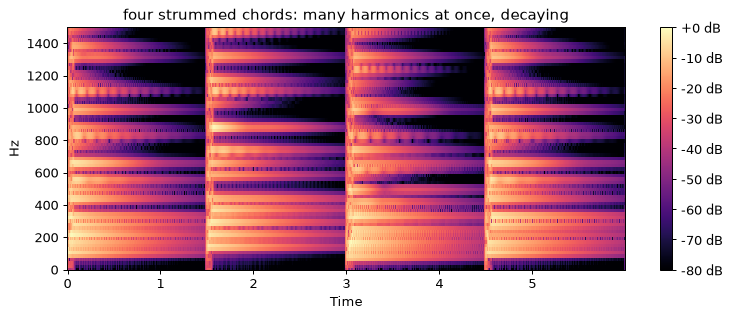

In [4]:
guitar = progression(["A", "D", "E", "A"], seconds_each=1.5)
play(guitar)
plot_spectrogram(guitar, fmax=1500, title="four strummed chords: many harmonics at once, decaying")
plt.show()

## 2.4 Chroma: "which of the 12 notes is sounding, now"

The spectrogram has thousands of frequency rows. To reason about notes we fold it into **12 rows**, one per
pitch class: all the energy near any C (in any octave) goes into row C, and so on. The result is called a
**chroma** (or pitch-class profile). It is a 12 × time matrix, a compact feature for harmony.

librosa computes it with a *constant-Q transform* (frequency bins spaced one per semitone instead of evenly
in Hz). The app smooths it over 0.5 s, because chords last longer than single strums, and normalises each
time frame so its strongest pitch class is 1. That is `analysis.harmony_map(...)`.

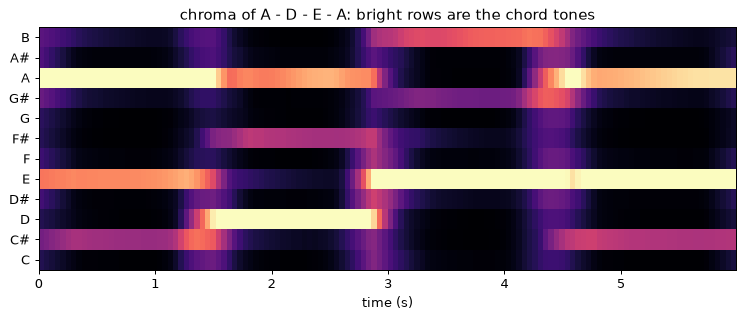

at 0.7 s (A chord), strongest pitch classes: ['A', 'E', 'C#']
at 2.2 s (D chord), strongest pitch classes: ['A', 'D', 'F#']
at 3.7 s (E chord), strongest pitch classes: ['E', 'B', 'G#']


In [5]:
from songpolish.analysis import harmony_map, HARMONY_HOP
h = harmony_map(guitar, SR)
fig, ax = plt.subplots(figsize=(10, 3.5))
t = np.arange(h.chroma.shape[1]) * HARMONY_HOP / SR
ax.imshow(h.chroma, aspect="auto", origin="lower", extent=[0, t[-1], -0.5, 11.5], cmap="magma")
ax.set_yticks(range(12)); ax.set_yticklabels(NOTE_NAMES); ax.set_xlabel("time (s)")
ax.set_title("chroma of A - D - E - A: bright rows are the chord tones")
plt.show()
for name, s in [("A", 0.7), ("D", 2.2), ("E", 3.7)]:
    w = h.weights(int(s * SR), int((s + 0.5) * SR))
    print(f"at {s} s ({name} chord), strongest pitch classes:", [NOTE_NAMES[i] for i in np.argsort(w)[::-1][:3]])

`h.weights(start, end)` is what the pitch correction later asks: *"how much is each pitch class sounding
during this sung note?"* It mixes the local chord (70%) with the key's overall profile (30%), so a note is
judged against both the chord now and the key.

## 2.5 Detecting the key: correlation with templates

Which key is a passage in? A classic method from music psychology (**Krumhansl–Schmuckler**): listeners were
asked how well each of the 12 notes "fits" in a key, which gives a 12-number **profile** for major and one
for minor. To detect the key:

1. sum the chroma over time → a 12-number profile of the passage,
2. for each of the 24 keys (12 tonics × major/minor), rotate the template to that tonic (`np.roll`),
3. compute the **Pearson correlation** between the passage profile and the template,
4. the key with the highest correlation wins.

This is template matching, a nearest-neighbour classifier with 24 prototypes.

A major   correlation 0.94
E major   correlation 0.72
A minor   correlation 0.58
C# minor  correlation 0.54
D major   correlation 0.44


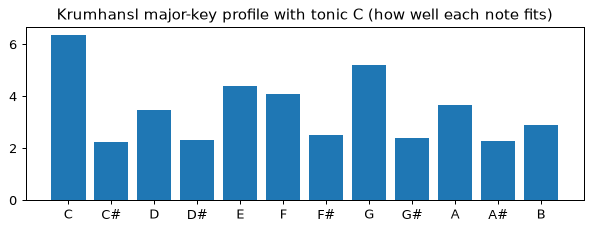

In [6]:
from songpolish.analysis import _key_scores, _MAJOR
scores = _key_scores(h.chroma.sum(axis=1))
best = sorted(scores.items(), key=lambda kv: -kv[1])[:5]
for key, r in best:
    print(f"{key.name:9s} correlation {r:.2f}")
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.bar(NOTE_NAMES, _MAJOR); ax.set_title("Krumhansl major-key profile with tonic C (how well each note fits)")
plt.show()

A major wins clearly here. The runners-up are E major (differs from A major by a single note) and
A minor (same tonic). On a real recording, with a singer, strumming noise and a ringing string, the margins
are much smaller: key detection is a soft decision. That matters in the next section.

## 2.6 Key changes over time: a Viterbi path

Some songs **modulate**: they move to a new key, often for the last chorus. The real song this app was
developed on goes from A major to C major at 3:19. With one key for the whole song, the app would "correct"
the ending into the wrong key (it did, at first).

Naive idea: detect the key in every 8-second window. Problem: windows flicker. A single E chord makes a
window look like "E major" for a moment. We want the key to change **only when the evidence is sustained**.

This is the classic setting for a **hidden Markov model / Viterbi decoding** (the same algorithm used in speech
recognition and part-of-speech tagging):

* **hidden states**: the 12 key signatures (a relative major/minor pair is one state, since they share notes),
* **emission score** of each window: its key correlation,
* **transition cost**: staying in a key is free, switching costs `KEY_CHANGE_COST` (3.0, in units of
  correlation × seconds),
* **Viterbi** finds the sequence of states that maximises total score minus switching costs, using dynamic programming.

A switch only pays off if the new key fits better by enough, for long enough. With a correlation advantage of
about 0.25, that takes about 12 s, so a single chord never switches the key.

Let's build a song that modulates: A–D–E in A major for 30 s, then C–G–F in C major for 30 s.

In [7]:
from songpolish.analysis import key_spans, KEY_CHANGE_COST
song = np.concatenate([progression(["A", "D", "E"] * 10)[0], progression(["C", "G", "F"] * 10)[0]])[None]
h2 = harmony_map(song, SR)
for span in h2.keys:
    print(f"{span.start / SR:5.1f} s - {span.end / SR:5.1f} s : {span.key.name}  ({' '.join(NOTE_NAMES[p] for p in span.key.pitch_classes)})")
print("key at 40 s:", h2.key_at(40 * SR, 41 * SR).name)

  0.0 s -  29.3 s : A major  (C# D E F# G# A B)
 29.3 s -  60.0 s : C major  (C D E F G A B)
key at 40 s: C major


The change is found within a couple of seconds of the real one (30 s). Below are the per-window scores of
the two competing key signatures, and the decoded path. The Viterbi path ignores short dips and switches once.

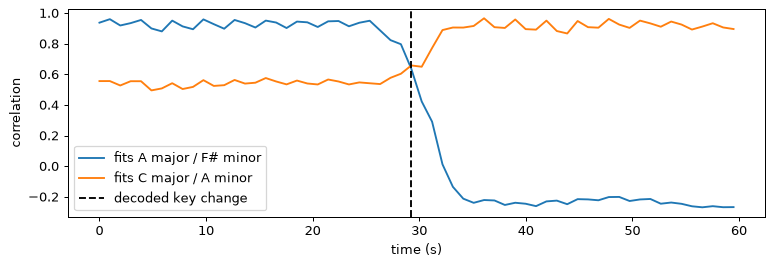

In [8]:
from songpolish.analysis import KEY_WINDOW_S, KEY_STEP_S
fps = SR / HARMONY_HOP
raw = librosa.feature.chroma_cqt(y=song[0], sr=SR, hop_length=HARMONY_HOP)
centers = np.arange(0, raw.shape[1], int(KEY_STEP_S * fps)); half = int(KEY_WINDOW_S * fps / 2)
fitA, fitC = [], []
for c in centers:
    sc = _key_scores(raw[:, max(0, c - half): c + half].sum(axis=1))
    fitA.append(max(sc[Key(9, False)], sc[Key(6, True)])); fitC.append(max(sc[Key(0, False)], sc[Key(9, True)]))
t = centers / fps
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, fitA, label="fits A major / F# minor"); ax.plot(t, fitC, label="fits C major / A minor")
ax.axvline(h2.keys[1].start / SR, color="k", ls="--", label="decoded key change")
ax.set_xlabel("time (s)"); ax.set_ylabel("correlation"); ax.legend(); plt.show()

### A caveat learned on the real song: drones

The guitarist in the real recording lets the open A string ring through the whole song. In the chroma, A is
then the strongest note at almost every moment, even under C or F chords. Any rule that trusts "the
strongest note" is fooled by that. Later notebooks show the places where the app had to remove each
note's average level before comparing (so a constant drone cancels out).

## 2.7 The tuning reference

Not every guitar is tuned to A = 440 Hz. If the guitar is 20 cents flat, "in tune" for the singer means
20 cents flat too: **the voice is tuned to the guitar, not to an abstract grid.** librosa estimates the
offset by looking at where spectral peaks fall between semitone lines (`librosa.estimate_tuning`). The
app does it on the guitar (`analysis.tuning_offset_cents`), uses it as the reference for every sung note,
and can optionally retune the whole song to 440. The estimate is good to a few cents, as the test shows;
below about 5 cents nobody hears a difference.

In [9]:
from songpolish.analysis import tuning_offset_cents
for cents in [0, -20, 15]:
    detuned = np.concatenate([plucked_chord([m + cents / 100 for m in CHORDS[c]], 1.5, seed=i) for i, c in enumerate(["A", "D", "E"])])[None]
    print(f"guitar tuned {cents:+d} cents -> measured {tuning_offset_cents(detuned):+.1f} cents")

guitar tuned +0 cents -> measured -3.0 cents


guitar tuned -20 cents -> measured -20.0 cents


guitar tuned +15 cents -> measured +16.0 cents


## Summary

* Pitch class = MIDI number mod 12. A key is 7 of the 12 pitch classes; a chord is 3 or more notes at once.
* **Chroma** folds the spectrum into 12 rows: a 12 × time feature matrix of "which notes are sounding".
* **Key detection** = correlation with rotated Krumhansl templates (template matching).
* **Key changes** = Viterbi decoding over 12 key-signature states with a switching cost, so only sustained
  changes count.
* The **tuning reference** is measured on the guitar, and the voice is tuned to it.

Next: **notebook 3**, finding what the voice actually sang.